In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# Added on_bad_lines='skip' to bypass rows with unexpected number of columns
df = pd.read_csv("house_prices.csv", on_bad_lines='skip')
print(df.head())
print(df.shape)

  Index                                              Title  \
0     0  1 BHK Ready to Occupy Flat for sale in Srushti...   
1     1  2 BHK Ready to Occupy Flat for sale in Dosti V...   
2     2  2 BHK Ready to Occupy Flat for sale in Sunrise...   
3     3        1 BHK Ready to Occupy Flat for sale Kasheli   
4     4  2 BHK Ready to Occupy Flat for sale in TenX Ha...   

                                         Description Amount(in rupees)  \
0  Bhiwandi, Thane has an attractive 1 BHK Flat f...           42 Lac    
1  One can find this stunning 2 BHK flat for sale...           98 Lac    
2  Up for immediate sale is a 2 BHK apartment in ...          1.40 Cr    
3  This beautiful 1 BHK Flat is available for sal...           25 Lac    
4  This lovely 2 BHK Flat in Pokhran Road, Thane ...          1.60 Cr    

  Price (in rupees) location Carpet Area         Status         Floor  \
0              6000    thane    500 sqft  Ready to Move  10 out of 11   
1             13799    thane    473 

/tmp/ipykernel_2137/1392675384.py:5: DtypeWarning: Columns (0,4,14,15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("house_prices.csv", on_bad_lines='skip')


In [ ]:
print("Before handling missing values\n",df.isnull().sum())

Before handling missing values
 Index                     0
Title                     0
Description            4759
Amount(in rupees)         1
Price (in rupees)     27165
location                  4
Carpet Area          122635
Status                  756
Floor                 11180
Transaction              85
Furnishing             4284
facing               103129
overlooking          122140
Society              169937
Bathroom                900
Balcony               73169
Car Parking          151164
Ownership             96765
Super Area           158690
Dimensions           279838
Plot Area            279838
dtype: int64


In [ ]:
df = df.drop(columns=[
    "Index",
    "Description",
    "Price (in rupees)",
    "facing",
    "overlooking",
    "Society",
    "Car Parking",
    "Super Area",
    "Dimensions",
    "Plot Area"
])
df=df.drop_duplicates()
print(df.shape)

(30611, 11)


In [ ]:
# Convert house prices into rupees
def clean_price(price):
    price = str(price).strip().lower()

    if "call for price" in price:
        return np.nan

    if "cr" in price:
        return float(price.replace("cr", "").strip()) * 10000000

    if "lac" in price:
        return float(price.replace("lac", "").strip()) * 100000

    return pd.to_numeric(price, errors="coerce")


df["House_Price"] = df["Amount(in rupees)"].apply(clean_price)
# Remove the original price column
df = df.drop(columns=["Amount(in rupees)"])
# Remove rows where the price is missing
df = df.dropna(subset=["House_Price"])
# Remove invalid prices
df = df[df["House_Price"] > 0].copy()
print(df[["House_Price"]].head())
print("Remaining rows:", len(df))

   House_Price
0    4200000.0
1    9800000.0
2   14000000.0
3    2500000.0
4   16000000.0
Remaining rows: 28935


In [ ]:
# Extract bedrooms, such as 2 from "2 BHK"
df["BHK"] = pd.to_numeric(
    df["Title"].str.extract(r"(\d+)\s*BHK")[0],
    errors="coerce"
)
# Extract carpet area, such as 500 from "500 sqft"
df["Carpet_Area"] = pd.to_numeric(
    df["Carpet Area"].astype(str).str.extract(r"([\d,]+\.?\d*)")[0]
    .str.replace(",", "", regex=False),
    errors="coerce"
)
# Convert bathroom and balcony counts into numbers
df["Bathroom"] = pd.to_numeric(df["Bathroom"], errors="coerce")
df["Balcony"] = pd.to_numeric(df["Balcony"], errors="coerce")
# Remove the original columns we no longer need
df = df.drop(columns=[
    "Title", "Carpet Area", "Super Area"
], errors="ignore")
# Remove zero or negative values from property measurements
for col in ["BHK", "Carpet_Area", "Bathroom", "Balcony"]:
    df.loc[df[col] <= 0, col] = np.nan

print(df.head())

  location         Status         Floor Transaction      Furnishing  Bathroom  \
0    thane  Ready to Move  10 out of 11      Resale     Unfurnished       1.0   
1    thane  Ready to Move   3 out of 22      Resale  Semi-Furnished       2.0   
2    thane  Ready to Move  10 out of 29      Resale     Unfurnished       2.0   
3    thane  Ready to Move    1 out of 3      Resale     Unfurnished       1.0   
4    thane  Ready to Move  20 out of 42      Resale     Unfurnished       2.0   

   Balcony             Ownership  House_Price  BHK  Carpet_Area  
0      2.0                   NaN    4200000.0  1.0        500.0  
1      NaN              Freehold    9800000.0  2.0        473.0  
2      NaN              Freehold   14000000.0  2.0        779.0  
3      1.0                   NaN    2500000.0  1.0        530.0  
4      NaN  Co-operative Society   16000000.0  2.0        635.0  


In [ ]:
# Fill missing numerical values
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


In [ ]:
# X contains property details
X = df.drop(columns=["House_Price"])

# y contains the price we want to predict
y = df["House_Price"]

# Convert text categories into numbers
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Features:", X.shape)
print("Target:", y.shape)

Features: (28935, 928)
Target: (28935,)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Split data: 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Predict house prices
predictions = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

Mean Absolute Error: 7417401.6
Root Mean Squared Error: 24620705.58
R2 Score: -0.4603


   Actual Price  Predicted Price
0     4500000.0      11768775.33
1     8200000.0       6689286.95
2     5500000.0       2826875.70
3     3600000.0      11623626.30
4    18500000.0      14464566.92
5    14500000.0      25238063.25
6    18100000.0      33527861.23
7     5500000.0       7141385.78
8     1300000.0      -8508560.72
9     6800000.0      10122834.42


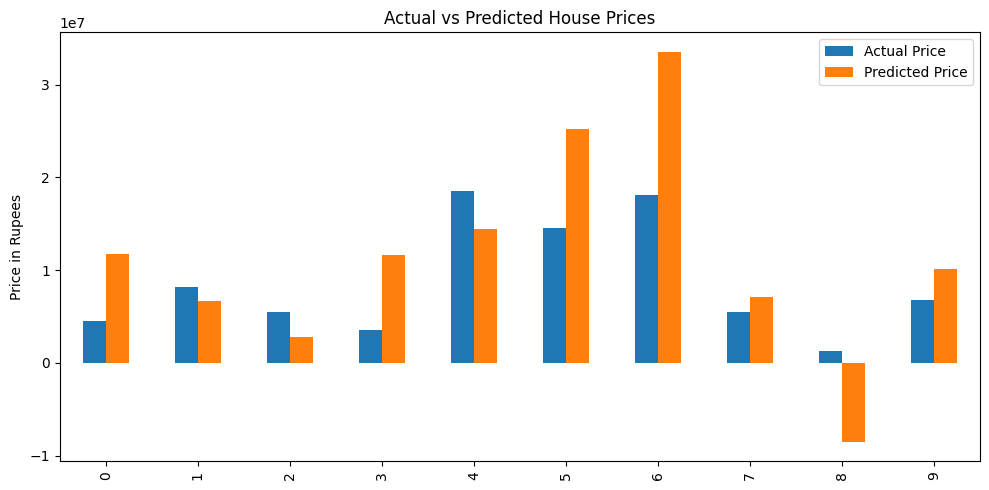

In [ ]:
# Compare the first 10 test predictions
result = pd.DataFrame({
    "Actual Price": y_test.iloc[:10].values,
    "Predicted Price": predictions[:10]
})

print(result.round(2))

# Plot the comparison
result.plot(kind="bar", figsize=(10, 5))

plt.title("Actual vs Predicted House Prices")
plt.ylabel("Price in Rupees")
plt.tight_layout()
plt.show()

In [ ]:

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the model
model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=20,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Predict house prices
predictions = model.predict(X_test)

# Calculate evaluation scores
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Decision Tree Results")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


Decision Tree Results
MAE: 5348563.48
RMSE: 13176483.54
R2 Score: 0.5818


In [ ]:
print(df.columns.tolist())

['location', 'Status', 'Floor', 'Transaction', 'Furnishing', 'Bathroom', 'Balcony', 'Ownership', 'House_Price', 'BHK', 'Carpet_Area']


In [ ]:
# Check if location is included in the model features
location_columns = [
    col for col in X.columns
    if "location" in col.lower()
]

print("Location features found:", len(location_columns))
print(location_columns[:20])

Location features found: 17
['location_1950 sqft', 'location_400 sqft', 'location_ahmedabad', 'location_bangalore', 'location_chennai', 'location_gurgaon', 'location_hyderabad', 'location_indore', 'location_jaipur', 'location_kolkata', 'location_lucknow', 'location_mumbai', 'location_nagpur', 'location_navi-mumbai', 'location_new-delhi', 'location_noida', 'location_thane']


In [ ]:
X = df.drop(columns=["House_Price"])
y = df["House_Price"]

X = pd.get_dummies(X, drop_first=True, dtype=int)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
# Get predictions for the test data
tree_predictions = tree_model.predict(X_test)

# Display actual and predicted prices for 10 houses
results = pd.DataFrame({
    "Actual Price": y_test.iloc[:10].values,
    "Predicted Price": tree_predictions[:10]
})

print(results.round(2))

   Actual Price  Predicted Price
0     4500000.0       7947922.08
1     8200000.0       7538580.97
2     5500000.0       4907731.59
3     3600000.0       7651659.75
4    18500000.0      14081605.93
5    14500000.0      14081605.93
6    18100000.0      12979230.77
7     5500000.0       7098949.24
8     1300000.0       1737857.14
9     6800000.0       6184339.62
